In [1]:
import matplotlib.pyplot as plt
import numpy as np
#import control
from numpy import sin, cos, tan, pi
from control import TransferFunction as TF

In [2]:
from krauss_misc import rwkos

In [36]:
import os, shutil, glob

In [4]:
import pylab_util as PU

In [5]:
rwkos.make_dir("figs")

In [6]:
rwkos.make_dir("csv_files")

In [7]:
import random_bode_generator as rbg

In [8]:
plt.rcParams['font.size'] = 14

## Example 1

In [9]:
p1 = 5.3*2*pi
G1 = TF(3,[1,p1,0])
G1

TransferFunction(
array([3]),
array([ 1.        , 33.30088213,  0.        ]),
outputs=1, inputs=1)

cmd=epstopdf figs/bode_id_001.eps
pdfcrop figs/bode_id_001.pdf figs/bode_id_001.pdf
PDFCROP 1.42, 2023/04/15 - Copyright (c) 2002-2023 by Heiko Oberdiek, Oberdiek Package Support Group.
==> 1 page written on `figs/bode_id_001.pdf'.


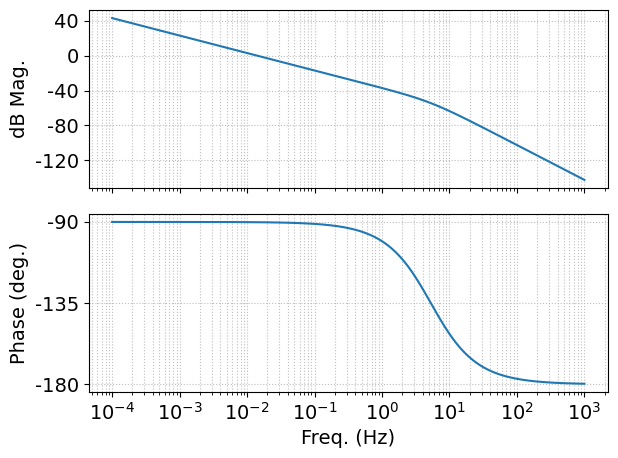

In [10]:
rbg.plot_bode_for_TF(G1)
plt.tight_layout()
PU.mysave("figs/bode_id_001.eps")

In [11]:
rbg.save_bode_to_csv(G1,basename="csv_files/bode_id")

pat = csv_files/bode_id_001*.csv
pat = csv_files/bode_id_002*.csv
pat = csv_files/bode_id_003*.csv


'csv_files/bode_id_003_11_04_2026_12_08PM.csv'

In [12]:
rbg.get_csv_filename("csv_files/bode_id")

pat = csv_files/bode_id_001*.csv
pat = csv_files/bode_id_002*.csv
pat = csv_files/bode_id_003*.csv
pat = csv_files/bode_id_004*.csv


'csv_files/bode_id_004_11_04_2026_12_08PM.csv'

## Example 2

In [13]:
w1 = 0.5*2*pi
z1 = 0.2
p2 = 12.3*2*pi
part2_1 = TF(w1**2,[1,2*z1*w1,w1**2])
part2_2 = TF(5, [1,p2])
G2 = part2_1*part2_2

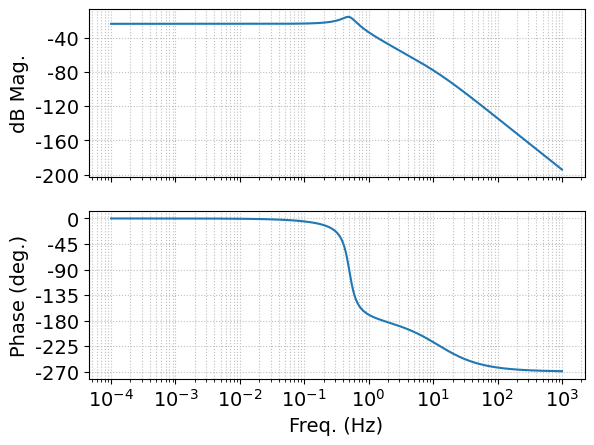

In [14]:
rbg.plot_bode_for_TF(G2)

In [16]:
rbg.save_bode_to_csv(G2,basename="csv_files/bode_id")

pat = csv_files/bode_id_001*.csv
pat = csv_files/bode_id_002*.csv


'csv_files/bode_id_002_11_04_2026_12_09PM.csv'

### Automating slide generation

Given:

- TF
- subscript

Do:

- save Bode to `figs`
- save csv to `csv_files`
- create md for slide and copy to clipboard
    - `## Bode ID Example %i`
    - what is the TF for this Bode plot?
    - `<img src="%s" width=600px>`
    - `:fh:0.7`

In [20]:
plt.tight_layout()
PU.mysave("figs/bode_id_002.eps")

cmd=epstopdf figs/bode_id_002.eps
pdfcrop figs/bode_id_002.pdf figs/bode_id_002.pdf
PDFCROP 1.42, 2023/04/15 - Copyright (c) 2002-2023 by Heiko Oberdiek, Oberdiek Package Support Group.

!!! Warning: Empty Bounding Box is returned by Ghostscript!
!!!   Page 1: 0 0 0 0
!!! Either there is a problem with the page or with Ghostscript.
!!! Recovery is tried by embedding the page in its original size.

==> 1 page written on `figs/bode_id_002.pdf'.


<Figure size 640x480 with 0 Axes>

In [31]:
rwkos.glob_all_subdirs('.',"myfig")

[]

In [17]:
import utils_345

In [29]:
import importlib

In [32]:
importlib.reload(utils_345)

<module 'utils_345' from '/Users/kraussry/git/teaching/utils_345.py'>

In [35]:
utils_345.create_slide_local_image("*002*.png", "Bode ID Example 2", "- what is the TF for this Bode plot?")

outlist: ['## Bode ID Example 2', '', '- what is the TF for this Bode plot?', '', '<img src="figs/bode_id_002.png" width=800px>', ':fh: 0.7', '']


'## Bode ID Example 2\n\n- what is the TF for this Bode plot?\n\n<img src="figs/bode_id_002.png" width=800px>\n:fh: 0.7\n'

In [26]:
outlist = ['## Bode ID Example 2', '', None, ':fh: 0.8', '']

In [28]:
",".join(outlist)

TypeError: sequence item 2: expected str instance, NoneType found

In [58]:
def gen_one_slide(G, subscript):
    file_pat = "csv_files/bode_id_%0.3i*.csv" % subscript
    matches = glob.glob(file_pat)
    if not matches:
        rbg.save_bode_to_csv(G,basename="csv_files/bode_id")
    eps_path = "figs/bode_id_%0.3i.eps" % subscript
    rbg.plot_bode_for_TF(G)
    plt.tight_layout()
    PU.mysave(eps_path)

    mytitle = "Bode ID Example %i" % subscript
    search_pat = "*bode_id_%0.3i*.png" % subscript
    utils_345.create_slide_local_image(search_pat, mytitle, "- what is the TF for this Bode plot?")

## Example 3

In [59]:
z3 = 0.4
w3 = 0.54*2*pi
G3 = TF([1,0],[1,2*z3*w3,w3**2])
G3

TransferFunction(
array([1, 0]),
array([ 1.        ,  2.71433605, 11.51190657]),
outputs=1, inputs=1)

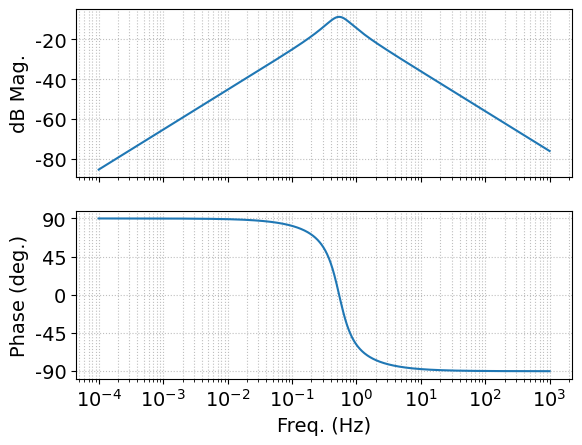

In [60]:
rbg.plot_bode_for_TF(G3)

cmd=epstopdf figs/bode_id_003.eps
pdfcrop figs/bode_id_003.pdf figs/bode_id_003.pdf
PDFCROP 1.42, 2023/04/15 - Copyright (c) 2002-2023 by Heiko Oberdiek, Oberdiek Package Support Group.
==> 1 page written on `figs/bode_id_003.pdf'.
outlist: ['## Bode ID Example 3', '', '- what is the TF for this Bode plot?', '', '<img src="figs/bode_id_003.png" width=800px>', ':fh: 0.7', '']


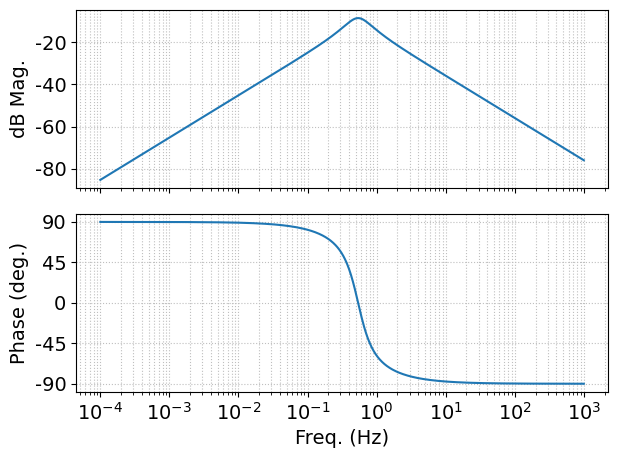

In [61]:
gen_one_slide(G3,3)